# Kho dữ liệu giá nông sản — Thiết kế, vật chất hoá khối và trình diễn OLAP

**Học phần INT1422 — Bài tập lớn, phần 1–4** (dữ liệu · thiết kế kho · cài đặt & tính khối · dịch vụ OLAP).
Notebook truy vấn trực tiếp kho ClickHouse do luồng ETL của nhóm nạp (Airflow DAG `ttns_price_pipeline`).

## 0. Câu hỏi nghiệp vụ
Kho được xây để trả lời các câu hỏi mà người thật sẽ hành động theo:

| # | Câu hỏi | Ai dùng | Thao tác OLAP |
|---|---|---|---|
| Q1 | Giá rau quả bán lẻ biến động thế nào theo năm / quý; năm nay đắt hay rẻ hơn năm trước? | người tiêu dùng, cơ quan quản lý giá | cuộn lên, cắt lát |
| Q2 | Mặt hàng nào tăng giá mạnh nhất so với cùng kỳ? | doanh nghiệp bán lẻ (điều chỉnh nhập hàng) | khoan xuống, top-N |
| Q3 | Giá tới tay người mua gấp bao nhiêu lần giá thu mua tại vườn? | nông dân, hợp tác xã, cơ quan quản lý | cắt khối, xoay |
| Q4 | Tháng nào trong năm giá rẻ / đắt nhất (mùa vụ) ở từng vùng? | thương lái, doanh nghiệp thu mua | khoan xuống, xoay |

In [1]:
import io
import os
import time
import uuid
from itertools import product as iproduct

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyBboxPatch

CH_URL = os.getenv("CLICKHOUSE_URL", "http://localhost:8123")
CH_AUTH = ("default", os.getenv("CLICKHOUSE_PASSWORD", "mypassword"))
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda v: f"{v:,.0f}" if abs(v) >= 100 else f"{v:,.2f}")

SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
S1, S2, S3, S4 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
CAP_COLOR = {"Bán lẻ": S1, "Thu mua": S2, "Bán buôn": S3}
plt.rcParams.update({
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10, "figure.facecolor": SURF, "axes.facecolor": SURF,
    "savefig.facecolor": SURF, "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True, "xtick.color": MUTED,
    "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "axes.labelcolor": INK2,
    "axes.titlesize": 12.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "lines.linewidth": 2,
    "legend.frameon": False, "savefig.dpi": 200, "savefig.bbox": "tight",
})
os.makedirs("figures", exist_ok=True)


def q(sql: str, query_id: str | None = None) -> pd.DataFrame:
    """Chạy SQL trên ClickHouse, trả DataFrame."""
    params = {"query_id": query_id} if query_id else {}
    r = requests.post(CH_URL, params=params, data=(sql.strip() + "\nFORMAT CSVWithNames").encode("utf-8"),
                      auth=CH_AUTH, timeout=120)
    if r.status_code != 200:
        raise RuntimeError(r.text[:500])
    return pd.read_csv(io.StringIO(r.text)) if r.text.strip() else pd.DataFrame()


def show_sql(sql: str):
    display(Markdown(f"```sql\n{sql.strip()}\n```"))


print(q("SELECT version() AS clickhouse, now() AS luc_chay").to_string(index=False))

clickhouse            luc_chay
26.9.16.11 2026-10-20 10:37:42


## 1. Dữ liệu nguồn và chất lượng dữ liệu
**Nguồn:** cổng *thitruongnongsan.gov.vn* (cơ sở dữ liệu "Giá rau quả trong nước", do cộng tác viên địa phương báo
giá), thu bằng script giả lập thao tác "Xuất excel" trên trang ASP.NET. File gốc được lưu **nguyên vẹn** trong
Data Lake MinIO (`raw-data/ttns/dt=…/`). Dữ liệu công khai trên cổng thông tin nhà nước, dùng cho mục đích học tập;
không chứa dữ liệu cá nhân.

In [2]:
from minio import Minio

mc = Minio(os.getenv("MINIO_HOST", "localhost:9000"), access_key="minioadmin", secret_key="minioadmin", secure=False)
raw_keys = sorted(o.object_name for o in mc.list_objects("raw-data", prefix="ttns/", recursive=True)
                  if o.object_name.endswith("_all.xlsx"))
latest = raw_keys[-1]
resp = mc.get_object("raw-data", latest)
raw = pd.read_excel(io.BytesIO(resp.read()))
resp.close()
print(f"File gốc mới nhất: raw-data/{latest}")
ym = raw["Năm"] * 100 + raw["Tháng"]
print(f"{len(raw):,} bản ghi × {raw.shape[1]} thuộc tính; thời gian {ym.min() % 100:02d}/{ym.min() // 100} → "
      f"{ym.max() % 100:02d}/{ym.max() // 100} (theo tháng, {ym.nunique()} tháng)")

File gốc mới nhất: raw-data/ttns/dt=2026-10-20/cat102_item6_all.xlsx
40,575 bản ghi × 11 thuộc tính; thời gian 04/2021 → 12/2025 (theo tháng, 57 tháng)


In [3]:
quality = pd.DataFrame({
    "kiểu": raw.dtypes.astype(str),
    "số giá trị khác nhau": raw.nunique(),
    "số ô thiếu": raw.isna().sum(),
    "tỷ lệ thiếu": (raw.isna().mean() * 100).round(2).astype(str) + "%",
})
quality["xử lý trong ETL (pipelines/ttns/cleaning.py)"] = [
    "chuẩn hoá Unicode NFC, bỏ khoảng trắng thừa",
    "gộp biến thể hoa thường (\"Sầu Riêng\"/\"Sầu riêng\") + bảng NAME_ALIASES",
    "gộp biến thể hoa thường + alias",
    "kiểm tra 2000-2100; dòng lỗi bị loại",
    "kiểm tra 1-12; dòng lỗi bị loại",
    "bỏ dòng ≤ 0; đánh dấu is_outlier nếu lệch > 5 lần trung vị cùng mặt hàng/đơn vị/cấp giá",
    "chuẩn hoá chuỗi",
    "THIẾU → suy ra từ các dòng khác cùng tỉnh cũ (phân cấp tỉnh cũ → tỉnh mới)",
    "chỉ 1 giá trị (CTV địa phương) - giữ làm siêu dữ liệu",
    "gộp 7 loại giá → 3 cấp giá (chiều Loại giá)",
    "15 cách viết → 6 đơn vị chuẩn (VNĐ/kg, VNĐ/chục quả…)",
]
quality

,kiểu,số giá trị khác nhau,số ô thiếu,tỷ lệ thiếu,xử lý trong ETL (pipelines/ttns/cleaning.py)
Nhóm sản phẩm,object,2,0,0.0%,"chuẩn hoá Unicode NFC, bỏ khoảng trắng thừa"
Sản phẩm,object,84,0,0.0%,"gộp biến thể hoa thường (""Sầu Riêng""/""Sầu riên..."
Tên_mặt_hàng,object,218,0,0.0%,gộp biến thể hoa thường + alias
Năm,int64,5,0,0.0%,kiểm tra 2000-2100; dòng lỗi bị loại
Tháng,int64,12,0,0.0%,kiểm tra 1-12; dòng lỗi bị loại
Giá,int64,291,0,0.0%,bỏ dòng ≤ 0; đánh dấu is_outlier nếu lệch > 5 ...
Thị_trường,object,15,0,0.0%,chuẩn hoá chuỗi
Thị_trường (tên mới),object,9,33,0.08%,THIẾU → suy ra từ các dòng khác cùng tỉnh cũ (...
Nguồn,object,1,0,0.0%,chỉ 1 giá trị (CTV địa phương) - giữ làm siêu ...
Loại_giá,object,7,0,0.0%,gộp 7 loại giá → 3 cấp giá (chiều Loại giá)


**Nhận xét:** cột duy nhất bị thiếu là *Thị trường (tên mới)* (tỉnh sau sáp nhập 2025) — điền bằng phụ thuộc hàm
tỉnh cũ → tỉnh mới lấy từ chính dữ liệu, không đoán. Ngoài ô thiếu, chất lượng dữ liệu còn bị ảnh hưởng bởi
**thiếu nhất quán** (cùng sản phẩm viết nhiều kiểu, đơn vị viết 15 kiểu) và **nhiễu** (giá nhập thừa / thiếu số 0) —
hai vấn đề này đều được xử lý ở bước ETL trước khi vào kho.

## 2. Thiết kế kho dữ liệu
### 2.1 Lược đồ hình sao

In [4]:
tables = q("""
SELECT name AS bang, total_rows AS so_dong, engine
FROM system.tables WHERE database = 'ttns' AND engine NOT LIKE '%View%' ORDER BY name""")
cols = q("""
SELECT table AS bang, groupArray(name) AS cot FROM system.columns
WHERE database = 'ttns' GROUP BY table""").set_index("bang")["cot"]
tables["cột"] = tables["bang"].map(cols)
tables

,bang,so_dong,engine,cột
0,cdc_log,14674,MergeTree,"['run_date','scope','product_id','market_id','..."
1,cube_nam_mathang_tinh_loaigia,1111,AggregatingMergeTree,"['year','product_id','nhom_san_pham','san_pham..."
2,cube_quy_mathang_tinh_loaigia,2767,AggregatingMergeTree,"['year','quarter','product_id','nhom_san_pham'..."
3,cube_thang_nhom_tinh_loaigia,762,AggregatingMergeTree,"['year','quarter','month','nhom_san_pham','mar..."
4,dim_date,228,ReplacingMergeTree,"['date_id','first_day','year','quarter','month']"
5,dim_market,60,ReplacingMergeTree,"['market_id','tinh_cu','tinh_moi','vung']"
6,dim_price_type,28,ReplacingMergeTree,"['loai_gia','cap_gia','mo_ta']"
7,dim_product,836,ReplacingMergeTree,"['product_id','nhom_san_pham','san_pham','mat_..."
8,fact_price_monthly,7337,ReplacingMergeTree,"['product_id','market_id','date_id','loai_gia'..."
9,ml_cluster,122,MergeTree,"['nhom_san_pham','san_pham','mat_hang','tinh_c..."


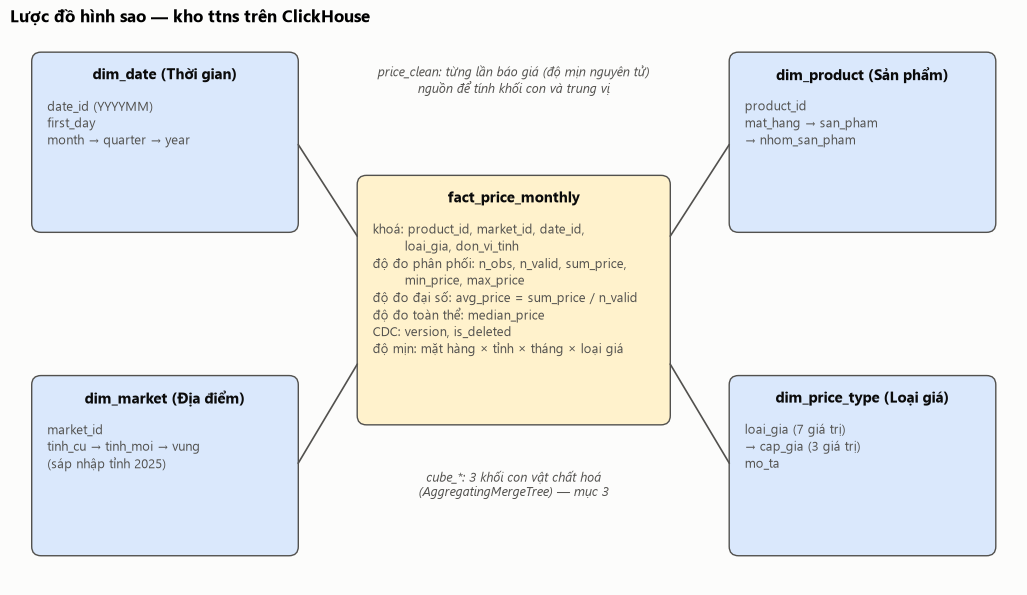

In [5]:
def draw_star():
    fig, ax = plt.subplots(figsize=(13, 7.2))
    ax.set_xlim(0, 13)
    ax.set_ylim(0, 7.2)
    ax.axis("off")

    def box(x, y, w, h, title, lines, color):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.12",
                                    facecolor=color, edgecolor=INK2, linewidth=1))
        ax.text(x + w / 2, y + h - 0.28, title, ha="center", va="center", fontsize=11, fontweight="bold", color=INK)
        ax.text(x + 0.18, y + h - 0.58, "\n".join(lines), ha="left", va="top", fontsize=9, color=INK2,
                linespacing=1.45)

    fact = (4.5, 2.1, 4.0, 3.2)
    box(*fact, "fact_price_monthly", [
        "khoá: product_id, market_id, date_id,", "        loai_gia, don_vi_tinh",
        "độ đo phân phối: n_obs, n_valid, sum_price,", "        min_price, max_price",
        "độ đo đại số: avg_price = sum_price / n_valid", "độ đo toàn thể: median_price",
        "CDC: version, is_deleted", "độ mịn: mặt hàng × tỉnh × tháng × loại giá"], "#fff2cc")
    dims = [
        ((0.3, 4.6, 3.4, 2.3), "dim_date (Thời gian)", ["date_id (YYYYMM)", "first_day", "month → quarter → year"]),
        ((9.3, 4.6, 3.4, 2.3), "dim_product (Sản phẩm)", ["product_id", "mat_hang → san_pham", "→ nhom_san_pham"]),
        ((0.3, 0.4, 3.4, 2.3), "dim_market (Địa điểm)", ["market_id", "tinh_cu → tinh_moi → vung", "(sáp nhập tỉnh 2025)"]),
        ((9.3, 0.4, 3.4, 2.3), "dim_price_type (Loại giá)", ["loai_gia (7 giá trị)", "→ cap_gia (3 giá trị)", "mo_ta"]),
    ]
    for (x, y, w, h), title, lines in dims:
        box(x, y, w, h, title, lines, "#dae8fc")
        cx, cy = x + w / 2, y + h / 2
        fx = fact[0] if cx < fact[0] else fact[0] + fact[2]
        ax.annotate("", xy=(fx, fact[1] + fact[3] / 2 + (0.8 if cy > 3.6 else -0.8)), xytext=(x + (w if cx < fx else 0), cy),
                    arrowprops=dict(arrowstyle="-", color=INK2, linewidth=1.2))
    ax.text(6.5, 6.55, "price_clean: từng lần báo giá (độ mịn nguyên tử)\nnguồn để tính khối con và trung vị",
            ha="center", va="center", fontsize=9, color=INK2, style="italic")
    ax.text(6.5, 1.3, "cube_*: 3 khối con vật chất hoá\n(AggregatingMergeTree) — mục 3", ha="center", va="center",
            fontsize=9, color=INK2, style="italic")
    ax.set_title("Lược đồ hình sao — kho ttns trên ClickHouse")
    fig.savefig("figures/01_luoc_do_hinh_sao.png")
    plt.show()


draw_star()

### 2.2 Độ mịn, chiều và phân cấp khái niệm
**Độ mịn của bảng sự kiện = 1 mặt hàng × 1 tỉnh × 1 tháng × 1 loại giá × 1 đơn vị tính.**
- *Vì sao tháng, không phải ngày:* nguồn chỉ công bố theo tháng (không có cột ngày) — mịn hơn là bịa dữ liệu.
- *Vì sao mặt hàng chứ không phải sản phẩm:* giá "Bưởi năm roi" và "Bưởi da xanh" khác nhau tới 2 lần; gộp sớm sẽ
  mất thông tin. Mức sản phẩm vẫn có được nhờ cuộn lên.
- *Vì sao giữ loại giá ở độ mịn:* giá bán lẻ và giá thu mua là hai đại lượng khác bản chất, cộng lẫn là sai.
- *Vì sao có thêm bảng `price_clean` (từng lần báo giá):* trung vị là độ đo toàn thể — muốn có trung vị ở mức quý /
  năm phải tính từ dữ liệu nguyên tử, không tính được từ trung vị tháng.

| Chiều | Phân cấp (mịn → thô) | Số giá trị mỗi mức |
|---|---|---|
| Thời gian | tháng → quý → năm | 57 → 19 → 5 |
| Sản phẩm | mặt hàng → sản phẩm → nhóm | 209 → 78 (73 tên, vài tên nằm ở cả 2 nhóm) → 2 |
| Địa điểm | tỉnh cũ → tỉnh mới → vùng | 15 → 9 → 4 |
| Loại giá | loại giá → cấp giá | 7 → 3 |

In [6]:
levels = q("""
SELECT 'Thời gian' AS chieu, uniqExact(date_id) AS muc_1, uniqExact((year, quarter)) AS muc_2, uniqExact(year) AS muc_3
FROM ttns.dim_date FINAL
UNION ALL SELECT 'Sản phẩm', uniqExact(product_id), uniqExact((nhom_san_pham, san_pham)), uniqExact(nhom_san_pham)
FROM ttns.dim_product FINAL
UNION ALL SELECT 'Địa điểm', uniqExact(tinh_cu), uniqExact(tinh_moi), uniqExact(vung) FROM ttns.dim_market FINAL
UNION ALL SELECT 'Loại giá', uniqExact(loai_gia), uniqExact(cap_gia), 0 FROM ttns.dim_price_type FINAL""")
levels

,chieu,muc_1,muc_2,muc_3
0,Sản phẩm,209,78,2
1,Địa điểm,15,9,4
2,Thời gian,57,19,5
3,Loại giá,7,3,0


### 2.3 Số khối con
Công thức (Bài 5): $T = \prod_{i=1}^{n} (L_i + 1)$ với $L_i$ là số mức của chiều $i$, cộng 1 cho mức "tất cả".

$T = (3+1) \times (3+1) \times (3+1) \times (2+1) = 4 \times 4 \times 4 \times 3 = \mathbf{192}$ khối con
(không có phân cấp thì chỉ $2^4 = 16$). Không thể và không nên vật chất hoá cả 192 → **vật chất hoá một phần**.

## 3. Chọn khối con để vật chất hoá — thuật toán tham lam
**Thuật toán (Harinarayan, Rajaraman & Ullman; Bài 5 slide 27–28):**
- Chi phí trả lời một khối con *w* = số dòng của khối nhỏ nhất **đã vật chất hoá** mà trả lời được *w* (mọi chiều của
  khối đó mịn bằng hoặc mịn hơn *w*). Ban đầu chỉ có khối đáy.
- Mỗi vòng chọn khối *v* có **lợi ích** lớn nhất: $B(v) = \sum_{w \preceq v} \max(0, C(w) - |v|)$.
- Kích thước $|v|$ đo trên dữ liệu thật (số tổ hợp khác nhau của các chiều trên các lần báo giá hợp lệ, VNĐ/kg).

In [7]:
obs = q("""
SELECT c.date_id, c.nam, c.thang, c.product_id, c.san_pham, c.nhom_san_pham, c.market_id, c.tinh_moi, m.vung,
       c.loai_gia, c.cap_gia
FROM ttns.price_clean c LEFT JOIN (SELECT market_id, vung FROM ttns.dim_market FINAL) m ON c.market_id = m.market_id
WHERE c.is_outlier = 0 AND c.don_vi_tinh = 'VNĐ/kg'""")
obs["quy"] = obs["nam"] * 10 + (obs["thang"] - 1) // 3 + 1
obs["sp_key"] = obs["nhom_san_pham"] + "|" + obs["san_pham"]
LV = {"Thời gian": ["date_id", "quy", "nam", None], "Sản phẩm": ["product_id", "sp_key", "nhom_san_pham", None],
      "Địa điểm": ["market_id", "tinh_moi", "vung", None], "Loại giá": ["loai_gia", "cap_gia", None]}
LV_NAME = {"date_id": "tháng", "quy": "quý", "nam": "năm", "product_id": "mặt hàng", "sp_key": "sản phẩm",
           "nhom_san_pham": "nhóm", "market_id": "tỉnh cũ", "tinh_moi": "tỉnh mới", "vung": "vùng",
           "loai_gia": "loại giá", "cap_gia": "cấp giá", None: "*"}
nodes = list(iproduct(range(4), range(4), range(4), range(3)))


def node_cols(n):
    return [lv[i] for lv, i in zip(LV.values(), n) if lv[i]]


def node_name(n):
    return "(" + ", ".join(LV_NAME[lv[i]] for lv, i in zip(LV.values(), n)) + ")"


size = {n: (obs[node_cols(n)].drop_duplicates().shape[0] if node_cols(n) else 1) for n in nodes}
print(f"{len(obs):,} lần báo giá hợp lệ; {len(nodes)} khối con; khối đáy {node_name((0, 0, 0, 0))} = {size[(0, 0, 0, 0)]:,} dòng")


def answers(v, w):
    return all(a <= b for a, b in zip(v, w))


base = (0, 0, 0, 0)
cost = {w: size[base] for w in nodes}
rounds = [{"vòng": 0, "khối con chọn": node_name(base) + " — khối đáy", "số dòng": size[base], "lợi ích": None,
           "tổng chi phí 192 truy vấn": sum(cost.values())}]
chosen = [base]
for k in range(1, 7):
    best = max((v for v in nodes if v not in chosen),
               key=lambda v: sum(max(0, cost[w] - size[v]) for w in nodes if answers(v, w)))
    benefit = sum(max(0, cost[w] - size[best]) for w in nodes if answers(best, w))
    chosen.append(best)
    for w in nodes:
        if answers(best, w):
            cost[w] = min(cost[w], size[best])
    rounds.append({"vòng": k, "khối con chọn": node_name(best), "số dòng": size[best], "lợi ích": benefit,
                   "tổng chi phí 192 truy vấn": sum(cost.values())})
greedy = pd.DataFrame(rounds).set_index("vòng")
greedy["giảm so với chỉ có khối đáy"] = 1 - greedy["tổng chi phí 192 truy vấn"] / greedy.loc[0, "tổng chi phí 192 truy vấn"]
greedy.style.format({"số dòng": "{:,}", "lợi ích": "{:,.0f}", "tổng chi phí 192 truy vấn": "{:,}",
                     "giảm so với chỉ có khối đáy": "{:.0%}"})

38,296 lần báo giá hợp lệ; 192 khối con; khối đáy (tháng, mặt hàng, tỉnh cũ, loại giá) = 6,925 dòng


,khối con chọn,số dòng,lợi ích,tổng chi phí 192 truy vấn,giảm so với chỉ có khối đáy
vòng,,,,,
0,"(tháng, mặt hàng, tỉnh cũ, loại giá) — khối đáy","6,925",nan,"1,329,600",0%
1,"(quý, mặt hàng, tỉnh cũ, loại giá)","2,767","598,752","730,848",45%
2,"(tháng, nhóm, tỉnh cũ, loại giá)",762,"292,272","438,576",67%
3,"(năm, mặt hàng, tỉnh cũ, loại giá)","1,111","79,488","359,088",73%
4,"(quý, nhóm, tỉnh cũ, loại giá)",279,"34,776","324,312",76%
5,"(tháng, sản phẩm, tỉnh cũ, loại giá)","5,149","21,312","303,000",77%
6,"(*, mặt hàng, tỉnh cũ, loại giá)",429,"16,368","286,632",78%


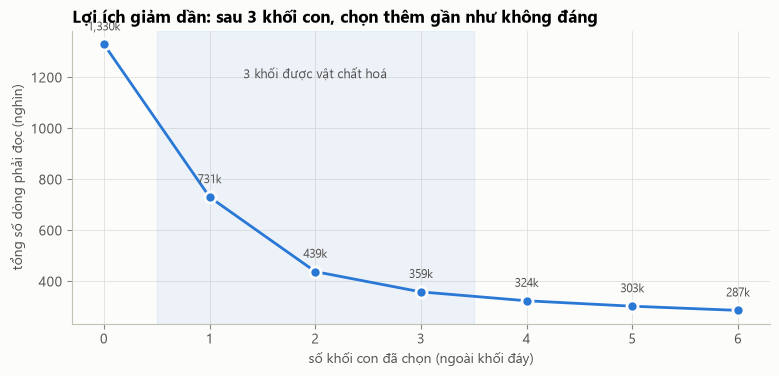

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(greedy.index, greedy["tổng chi phí 192 truy vấn"] / 1e3, color=S1, marker="o", markersize=8,
        markeredgecolor=SURF, markeredgewidth=2)
for k, v in greedy["tổng chi phí 192 truy vấn"].items():
    ax.annotate(f"{v / 1e3:,.0f}k", (k, v / 1e3), xytext=(0, 10), textcoords="offset points", ha="center",
                fontsize=8.5, color=INK2)
ax.axvspan(0.5, 3.5, color=S1, alpha=0.07)
ax.text(2, greedy["tổng chi phí 192 truy vấn"].max() / 1e3 * 0.9, "3 khối được vật chất hoá", ha="center",
        color=INK2, fontsize=9)
ax.set_xlabel("số khối con đã chọn (ngoài khối đáy)")
ax.set_ylabel("tổng số dòng phải đọc (nghìn)")
ax.set_title("Lợi ích giảm dần: sau 3 khối con, chọn thêm gần như không đáng")
fig.savefig("figures/02_tham_lam.png")
plt.show()

**Quyết định:** vật chất hoá **3 khối con đầu** (giảm ~73% tổng chi phí). Từ vòng 4, lợi ích cận biên giảm
mạnh trong khi mỗi khối thêm tốn dung lượng và thời gian dựng lại sau mỗi lần nạp. Ba khối này được DAG dựng lại sau
mỗi lần nạp dữ liệu (task `build_olap_cubes`, định nghĩa trong `dags/pipelines/ttns/olap.py`):

In [9]:
q("""
SELECT name AS khoi_con, total_rows AS so_dong, engine, comment AS ly_do
FROM system.tables WHERE database = 'ttns' AND name LIKE 'cube_%' ORDER BY total_rows DESC""")

,khoi_con,so_dong,engine,ly_do
0,cube_quy_mathang_tinh_loaigia,2767,AggregatingMergeTree,"vòng 1, lợi ích lớn nhất: gom 3 tháng -> phục ..."
1,cube_nam_mathang_tinh_loaigia,1111,AggregatingMergeTree,vòng 3: so sánh giá theo năm của từng mặt hàng...
2,cube_thang_nhom_tinh_loaigia,762,AggregatingMergeTree,"vòng 2: giữ độ mịn tháng (xu hướng, mùa vụ) nh..."


**Ghi chú:** thuật toán chọn giữ chiều Địa điểm và Loại giá ở mức mịn nhất vì hai chiều này có ít giá trị — giữ
chúng hầu như không làm khối to ra, trong khi lại trả lời được nhiều truy vấn hơn. Khối con lưu sẵn cả các mức cha
(ví dụ mặt hàng kèm sản phẩm, nhóm) nên cuộn lên trên khối không cần join bảng chiều.

### 3.1 Viết lại truy vấn theo khối con: đo lợi ích thật
Cùng một câu hỏi — *giá bán lẻ trung bình và trung vị theo năm và nhóm sản phẩm* — trả lời bằng (a) dữ liệu nguyên tử
và (b) khối con `cube_quy_mathang_tinh_loaigia`. Số dòng ClickHouse phải đọc lấy từ `system.query_log`.

In [10]:
SQL_BASE = """
SELECT c.nam AS nam, c.nhom_san_pham, count() AS n_bao_gia, round(avg(c.gia)) AS gia_tb,
       quantileExact(0.5)(c.gia) AS gia_trung_vi
FROM ttns.price_clean c
WHERE c.is_outlier = 0 AND c.don_vi_tinh = 'VNĐ/kg' AND c.cap_gia = 'Bán lẻ'
GROUP BY nam, c.nhom_san_pham ORDER BY nam, c.nhom_san_pham"""
SQL_CUBE = """
SELECT year AS nam, nhom_san_pham, sum(so_bao_gia) AS n_bao_gia, round(sum(tong_gia) / sum(so_bao_gia)) AS gia_tb,
       quantileExactMerge(0.5)(gia_tv) AS gia_trung_vi
FROM ttns.cube_quy_mathang_tinh_loaigia
WHERE cap_gia = 'Bán lẻ'
GROUP BY nam, nhom_san_pham ORDER BY nam, nhom_san_pham"""
ids = {"Dữ liệu nguyên tử (price_clean)": str(uuid.uuid4()), "Khối con cube_quy_mathang_tinh_loaigia": str(uuid.uuid4())}
r_base = q(SQL_BASE, ids["Dữ liệu nguyên tử (price_clean)"])
r_cube = q(SQL_CUBE, ids["Khối con cube_quy_mathang_tinh_loaigia"])
requests.post(CH_URL, data=b"SYSTEM FLUSH LOGS", auth=CH_AUTH)
time.sleep(0.5)
stats = q(f"""
SELECT query_id, read_rows AS so_dong_doc, query_duration_ms AS thoi_gian_ms
FROM system.query_log WHERE type = 'QueryFinish' AND query_id IN ({", ".join(f"'{v}'" for v in ids.values())})""")
stats["cách trả lời"] = stats["query_id"].map({v: k for k, v in ids.items()})
display(stats.set_index("cách trả lời")[["so_dong_doc", "thoi_gian_ms"]])
print("Kết quả hai cách giống hệt nhau:", r_base.equals(r_cube))
r_cube

,so_dong_doc,thoi_gian_ms
cách trả lời,,
Dữ liệu nguyên tử (price_clean),40575,16
Khối con cube_quy_mathang_tinh_loaigia,2767,11


Kết quả hai cách giống hệt nhau: True


,nam,nhom_san_pham,n_bao_gia,gia_tb,gia_trung_vi
0,2021,Rau củ quả,2138,15971,15000
1,2021,Trái cây,2667,26779,25000
2,2022,Rau củ quả,1469,18105,17000
3,2022,Trái cây,1501,30835,30000
4,2023,Rau củ quả,2207,19528,18000
5,2023,Trái cây,2006,37879,35000
6,2024,Rau củ quả,2762,22922,20000
7,2024,Trái cây,2381,43257,40000
8,2025,Rau củ quả,2575,21353,20000
9,2025,Trái cây,2228,40727,35000


Kết quả **giống hệt** (kể cả trung vị — nhờ lưu trạng thái `quantileExactState` thay vì lưu con số trung vị), nhưng
khối con đọc ít dòng hơn nhiều. Với dữ liệu nhỏ như ở đây thời gian chênh lệch không đáng kể; số dòng đọc mới là chỉ
số phản ánh đúng lợi ích khi dữ liệu lớn lên.

## 4. Năm thao tác OLAP trên dữ liệu thật
Độ đo dùng xuyên suốt: **giá trung bình (VNĐ/kg)** = `sum(tong_gia) / sum(so_bao_gia)` — độ đo đại số nên cuộn lên
đúng ở mọi mức. Truy vấn chạy trên khối con nhỏ nhất trả lời được (đúng nguyên tắc ở 3.1).

In [11]:
AVG = "round(sum(tong_gia) / sum(so_bao_gia))"

### 4.1 Cuộn lên (roll-up) — Thời gian: tháng → quý → năm (bán lẻ, trái cây)

Số ô: tháng 57 → quý 19 → năm 5


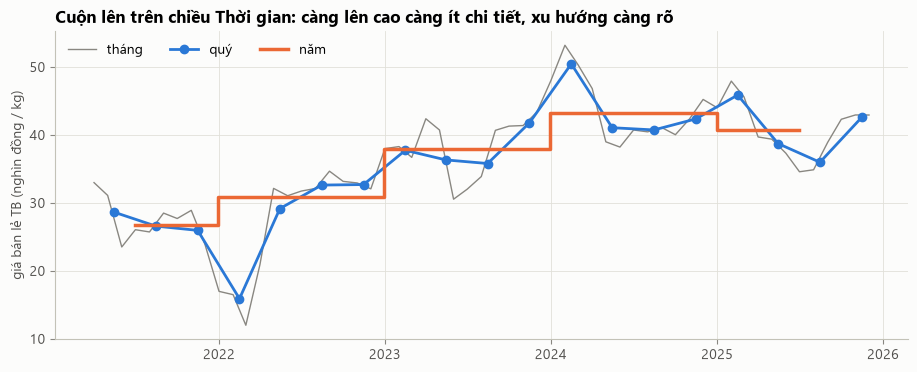

,year,gia_tb,n_bao_gia
0,2021,26779,2667
1,2022,30835,1501
2,2023,37879,2006
3,2024,43257,2381
4,2025,40727,2228


In [12]:
roll_month = q(f"""
SELECT year, month, {AVG} AS gia_tb FROM ttns.cube_thang_nhom_tinh_loaigia
WHERE cap_gia = 'Bán lẻ' AND nhom_san_pham = 'Trái cây' GROUP BY year, month ORDER BY year, month""")
roll_quarter = q(f"""
SELECT year, quarter, {AVG} AS gia_tb FROM ttns.cube_thang_nhom_tinh_loaigia
WHERE cap_gia = 'Bán lẻ' AND nhom_san_pham = 'Trái cây' GROUP BY year, quarter ORDER BY year, quarter""")
roll_year = q(f"""
SELECT year, {AVG} AS gia_tb, sum(so_bao_gia) AS n_bao_gia FROM ttns.cube_thang_nhom_tinh_loaigia
WHERE cap_gia = 'Bán lẻ' AND nhom_san_pham = 'Trái cây' GROUP BY year ORDER BY year""")
print(f"Số ô: tháng {len(roll_month)} → quý {len(roll_quarter)} → năm {len(roll_year)}")

fig, ax = plt.subplots(figsize=(11, 4))
t_m = pd.to_datetime(dict(year=roll_month["year"], month=roll_month["month"], day=1))
t_q = pd.to_datetime(dict(year=roll_quarter["year"], month=roll_quarter["quarter"] * 3 - 1, day=15))
t_y = pd.to_datetime(dict(year=roll_year["year"], month=7, day=1))
ax.plot(t_m, roll_month["gia_tb"] / 1000, color=MUTED, linewidth=1, label="tháng")
ax.plot(t_q, roll_quarter["gia_tb"] / 1000, color=S1, marker="o", markersize=6, label="quý")
ax.step(t_y, roll_year["gia_tb"] / 1000, where="mid", color=S2, linewidth=2.5, label="năm")
ax.set_ylabel("giá bán lẻ TB (nghìn đồng / kg)")
ax.set_title("Cuộn lên trên chiều Thời gian: càng lên cao càng ít chi tiết, xu hướng càng rõ")
ax.legend(loc="upper left", ncols=3)
fig.savefig("figures/03_cuon_len.png")
plt.show()
roll_year

### 4.2 Cuộn lên — Sản phẩm: mặt hàng → sản phẩm → nhóm (bán lẻ, năm 2025)

In [13]:
for level, cols_ in (("mặt hàng", "nhom_san_pham, san_pham, mat_hang"), ("sản phẩm", "nhom_san_pham, san_pham"),
                     ("nhóm", "nhom_san_pham")):
    r = q(f"""SELECT {cols_}, {AVG} AS gia_tb, sum(so_bao_gia) AS n_bao_gia FROM ttns.cube_nam_mathang_tinh_loaigia
              WHERE cap_gia = 'Bán lẻ' AND year = 2025 GROUP BY {cols_} ORDER BY n_bao_gia DESC""")
    print(f"\n— mức {level}: {len(r)} ô")
    display(r.head(5 if level != "nhóm" else 2))


— mức mặt hàng: 97 ô


,nhom_san_pham,san_pham,mat_hang,gia_tb,n_bao_gia
0,Rau củ quả,Cà chua,Cà chua,23937,231
1,Rau củ quả,Dưa chuột,Dưa chuột,21908,185
2,Rau củ quả,Khoai tây,Khoai tây,18503,185
3,Rau củ quả,Cà rốt,Cà rốt,20825,154
4,Trái cây,Ổi,Ổi,28265,151



— mức sản phẩm: 57 ô


,nhom_san_pham,san_pham,gia_tb,n_bao_gia
0,Rau củ quả,Rau cải,21168,339
1,Rau củ quả,Mướp,24420,238
2,Rau củ quả,Quả bí,17068,234
3,Rau củ quả,Cà chua,23937,231
4,Rau củ quả,Bắp cải,14704,213



— mức nhóm: 2 ô


,nhom_san_pham,gia_tb,n_bao_gia
0,Rau củ quả,21353,2575
1,Trái cây,40727,2228


### 4.3 Khoan xuống (drill-down) — Địa điểm: vùng → tỉnh mới → tỉnh cũ (giá thu mua, 2025)

In [14]:
DRILL = {
    "vùng": "vung",
    "tỉnh mới": "vung, tinh_moi",
    "tỉnh cũ": "vung, tinh_moi, tinh_cu",
}
for level, cols_ in DRILL.items():
    r = q(f"""SELECT {cols_}, {AVG} AS gia_thu_mua_tb, sum(so_bao_gia) AS n_bao_gia
              FROM ttns.cube_nam_mathang_tinh_loaigia WHERE cap_gia = 'Thu mua' AND year = 2025
              GROUP BY {cols_} ORDER BY {cols_}""")
    print(f"\n— mức {level}: {len(r)} ô")
    display(r)


— mức vùng: 2 ô


,vung,gia_thu_mua_tb,n_bao_gia
0,Đông Nam Bộ,11417,109
1,Đồng bằng sông Cửu Long,21941,5028



— mức tỉnh mới: 5 ô


,vung,tinh_moi,gia_thu_mua_tb,n_bao_gia
0,Đông Nam Bộ,Tây Ninh,11417,109
1,Đồng bằng sông Cửu Long,An Giang,20321,112
2,Đồng bằng sông Cửu Long,TP. Cần Thơ,21006,1570
3,Đồng bằng sông Cửu Long,Vĩnh Long,28371,912
4,Đồng bằng sông Cửu Long,Đồng Tháp,20210,2434



— mức tỉnh cũ: 9 ô


,vung,tinh_moi,tinh_cu,gia_thu_mua_tb,n_bao_gia
0,Đông Nam Bộ,Tây Ninh,Long An,11417,109
1,Đồng bằng sông Cửu Long,An Giang,An Giang,20321,112
2,Đồng bằng sông Cửu Long,TP. Cần Thơ,Cần Thơ,19320,623
3,Đồng bằng sông Cửu Long,TP. Cần Thơ,Hậu Giang,25932,587
4,Đồng bằng sông Cửu Long,TP. Cần Thơ,Sóc Trăng,15893,360
5,Đồng bằng sông Cửu Long,Vĩnh Long,Bến Tre,41820,437
6,Đồng bằng sông Cửu Long,Vĩnh Long,Vĩnh Long,15997,475
7,Đồng bằng sông Cửu Long,Đồng Tháp,Tiền Giang,20499,984
8,Đồng bằng sông Cửu Long,Đồng Tháp,Đồng Tháp,20013,1450


Khoan xuống cho thấy con số của vùng Đồng bằng sông Cửu Long là trung bình của nhiều tỉnh có mức giá khác nhau,
và tỉnh mới (sau sáp nhập) còn tách tiếp được thành các tỉnh cũ.

### 4.4 Cắt lát (slice) — cố định **một** chiều: Loại giá = Bán lẻ
Khối 4 chiều → khối 3 chiều; hiển thị 2 chiều (năm × nhóm) sau khi cuộn Địa điểm lên "tất cả".

In [15]:
SQL_SLICE = f"""
SELECT year, nhom_san_pham, {AVG} AS gia_tb
FROM ttns.cube_quy_mathang_tinh_loaigia
WHERE cap_gia = 'Bán lẻ'                          -- lát cắt
GROUP BY year, nhom_san_pham"""
show_sql(SQL_SLICE)
slice_ = q(SQL_SLICE).pivot(index="year", columns="nhom_san_pham", values="gia_tb")
slice_["thay đổi Trái cây so với năm trước"] = slice_["Trái cây"].pct_change().map(lambda v: f"{v:+.1%}" if pd.notna(v) else "")
slice_

```sql
SELECT year, nhom_san_pham, round(sum(tong_gia) / sum(so_bao_gia)) AS gia_tb
FROM ttns.cube_quy_mathang_tinh_loaigia
WHERE cap_gia = 'Bán lẻ'                          -- lát cắt
GROUP BY year, nhom_san_pham
```

nhom_san_pham,Rau củ quả,Trái cây,thay đổi Trái cây so với năm trước
year,,,
2021,15971,26779,
2022,18105,30835,+15.1%
2023,19528,37879,+22.8%
2024,22922,43257,+14.2%
2025,21353,40727,-5.8%


### 4.5 Cắt khối (dice) — chọn khoảng giá trị trên **nhiều** chiều
Năm ∈ {2024, 2025} **và** Nhóm = Trái cây **và** Vùng = Đồng bằng sông Cửu Long **và** Cấp giá = Thu mua → khối con
(quý × sản phẩm).

In [16]:
SQL_DICE = f"""
SELECT year, quarter, san_pham, {AVG} AS gia_thu_mua_tb, sum(so_bao_gia) AS n_bao_gia
FROM ttns.cube_quy_mathang_tinh_loaigia
WHERE year IN (2024, 2025) AND nhom_san_pham = 'Trái cây'
  AND vung = 'Đồng bằng sông Cửu Long' AND cap_gia = 'Thu mua'
GROUP BY year, quarter, san_pham"""
show_sql(SQL_DICE)
dice = q(SQL_DICE)
top_sp = dice.groupby("san_pham")["n_bao_gia"].sum().nlargest(8).index
dice_tbl = (dice[dice["san_pham"].isin(top_sp)].assign(ky=lambda x: x["year"].astype(str) + "-Q" + x["quarter"].astype(str))
            .pivot(index="san_pham", columns="ky", values="gia_thu_mua_tb"))
dice_tbl

```sql
SELECT year, quarter, san_pham, round(sum(tong_gia) / sum(so_bao_gia)) AS gia_thu_mua_tb, sum(so_bao_gia) AS n_bao_gia
FROM ttns.cube_quy_mathang_tinh_loaigia
WHERE year IN (2024, 2025) AND nhom_san_pham = 'Trái cây'
  AND vung = 'Đồng bằng sông Cửu Long' AND cap_gia = 'Thu mua'
GROUP BY year, quarter, san_pham
```

ky,2024-Q1,2024-Q2,2024-Q3,2024-Q4,2025-Q1,2025-Q2,2025-Q3,2025-Q4
san_pham,,,,,,,,
Bưởi,20726,21459,22128,21465,19833,20179,19860,20381
Cam,14581,15543,13635,13855,14053,11774,10546,12619
Chôm chôm,31492,27921,25875,25450,30811,22619,19303,30024
Dưa hấu,8921,8553,8415,9346,8540,8687,8897,9213
Nhãn,26915,29364,25872,25279,21543,22589,21824,24142
Sầu riêng,112519,81058,67577,94444,77191,59034,49983,59361
Thanh long,26475,29327,19433,15820,16667,19270,14176,18316
Xoài,32198,28044,33940,30470,29264,20293,22667,26600


### 4.6 Xoay trục (pivot) — đổi hàng và cột của cùng một kết quả
Hàng = sản phẩm, cột = năm (so sánh giá một sản phẩm qua các năm) → xoay thành hàng = năm, cột = sản phẩm (so sánh
các sản phẩm trong cùng một năm).

In [17]:
pv = q(f"""
SELECT san_pham, year, {AVG} AS gia_tb FROM ttns.cube_nam_mathang_tinh_loaigia
WHERE cap_gia = 'Bán lẻ' AND san_pham IN ('Xoài', 'Bưởi', 'Cam', 'Thanh long', 'Cà chua', 'Bắp cải')
GROUP BY san_pham, year""")
truoc = pv.pivot(index="san_pham", columns="year", values="gia_tb")
display(Markdown("**Trước khi xoay** (hàng = sản phẩm, cột = năm)"))
display(truoc)
display(Markdown("**Sau khi xoay** (hàng = năm, cột = sản phẩm)"))
truoc.T

**Trước khi xoay** (hàng = sản phẩm, cột = năm)

year,2021,2022,2023,2024,2025
san_pham,,,,,
Bưởi,28461,32974,59660,60728,53812
Bắp cải,14701,16169,12709,17010,14704
Cam,37993,36172,43348,47958,43112
Cà chua,19647,22492,23879,27486,23937
Thanh long,25405,23084,31952,37135,38827
Xoài,28894,28571,35803,39823,41767


**Sau khi xoay** (hàng = năm, cột = sản phẩm)

san_pham,Bưởi,Bắp cải,Cam,Cà chua,Thanh long,Xoài
year,,,,,,
2021,28461,14701,37993,19647,25405,28894
2022,32974,16169,36172,22492,23084,28571
2023,59660,12709,43348,23879,31952,35803
2024,60728,17010,47958,27486,37135,39823
2025,53812,14704,43112,23937,38827,41767


### 4.7 Toàn bộ mạng khối trong một truy vấn: `GROUP BY CUBE` và `ROLLUP`
`ROLLUP(year, quarter)` sinh các dòng tổng theo phân cấp (quý → năm → tất cả); `CUBE(nhom, cap_gia)` sinh cả
2² = 4 khối con. Hàm `grouping()` cho biết dòng nào là dòng tổng (chiều đó bị gộp thành "tất cả").

In [18]:
rollup = q(f"""
SELECT if(grouping(year) = 1, 'TẤT CẢ', toString(year)) AS nam,
       if(grouping(quarter) = 1, 'cả năm', concat('Q', toString(quarter))) AS quy,
       {AVG} AS gia_ban_le_tb, sum(so_bao_gia) AS n_bao_gia
FROM ttns.cube_quy_mathang_tinh_loaigia WHERE cap_gia = 'Bán lẻ' AND year >= 2024
GROUP BY ROLLUP(year, quarter) ORDER BY grouping(year), year, grouping(quarter), quarter""")
display(Markdown("**ROLLUP(năm, quý)** — giá bán lẻ 2024-2025"))
display(rollup)
cube = q(f"""
SELECT if(grouping(nhom_san_pham) = 1, '(tất cả)', nhom_san_pham) AS nhom,
       if(grouping(cap_gia) = 1, '(tất cả)', cap_gia) AS cap_gia_,
       {AVG} AS gia_tb, sum(so_bao_gia) AS n_bao_gia
FROM ttns.cube_quy_mathang_tinh_loaigia WHERE year = 2025
GROUP BY CUBE(nhom_san_pham, cap_gia) ORDER BY grouping(nhom_san_pham), grouping(cap_gia), nhom, cap_gia_""")
display(Markdown("**CUBE(nhóm, cấp giá)** — năm 2025: 4 khối con (nhóm×cấp giá), (nhóm), (cấp giá), ()"))
cube

**ROLLUP(năm, quý)** — giá bán lẻ 2024-2025

,nam,quy,gia_ban_le_tb,n_bao_gia
0,2024,Q1,35377,1150
1,2024,Q2,30764,1319
2,2024,Q3,31719,1412
3,2024,Q4,31899,1262
4,2024,cả năm,32336,5143
5,2025,Q1,31769,1331
6,2025,Q2,27991,1239
7,2025,Q3,27979,1285
8,2025,Q4,34604,948
9,2025,cả năm,30340,4803


**CUBE(nhóm, cấp giá)** — năm 2025: 4 khối con (nhóm×cấp giá), (nhóm), (cấp giá), ()

,nhom,cap_gia_,gia_tb,n_bao_gia
0,Rau củ quả,Bán lẻ,21353,2575
1,Rau củ quả,Thu mua,12073,602
2,Trái cây,Bán buôn,36549,91
3,Trái cây,Bán lẻ,40727,2228
4,Trái cây,Thu mua,22998,4535
5,Rau củ quả,(tất cả),19595,3177
6,Trái cây,(tất cả),28941,6854
7,(tất cả),Bán buôn,36549,91
8,(tất cả),Bán lẻ,30340,4803
9,(tất cả),Thu mua,21718,5137


## 5. Trả lời câu hỏi nghiệp vụ
### Q1 + Q2 — Năm 2025 đắt hay rẻ hơn 2024; mặt hàng nào tăng giá mạnh nhất? (thao tác dẫn xuất: top-N, tăng trưởng)

Giá bán lẻ TB: 2024 = 32,336đ/kg, 2025 = 30,340đ/kg (-6.2%); 45 sản phẩm có ≥ 20 lần báo giá mỗi năm


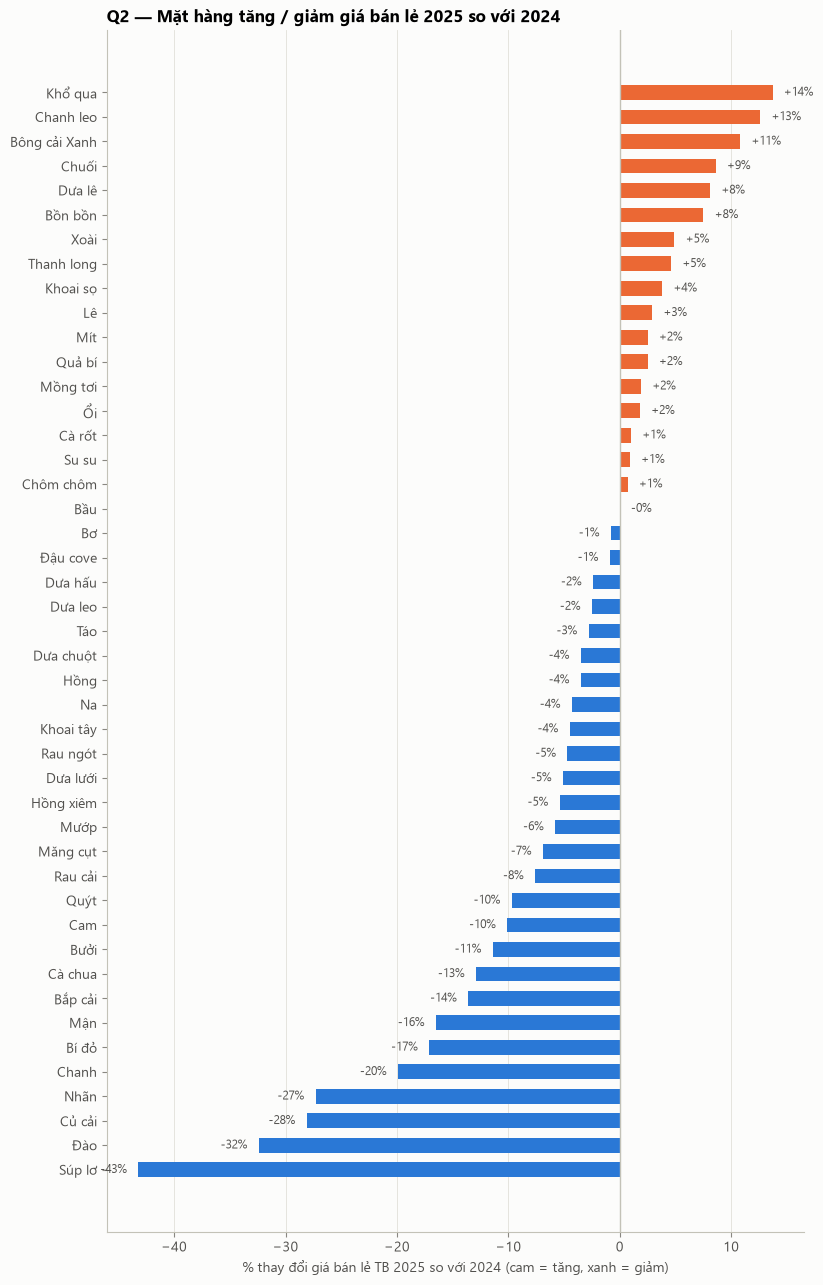

In [19]:
yoy = q(f"""
WITH g AS (
    SELECT san_pham, year, {AVG} AS gia_tb, sum(so_bao_gia) AS n
    FROM ttns.cube_nam_mathang_tinh_loaigia WHERE cap_gia = 'Bán lẻ' AND year IN (2024, 2025)
    GROUP BY san_pham, year)
SELECT a.san_pham, a.gia_tb AS gia_2024, b.gia_tb AS gia_2025, round((b.gia_tb / a.gia_tb - 1) * 100, 1) AS tang_pct,
       least(a.n, b.n) AS so_bao_gia_it_nhat
FROM g a JOIN g b ON a.san_pham = b.san_pham AND a.year = 2024 AND b.year = 2025
WHERE least(a.n, b.n) >= 20
ORDER BY tang_pct DESC""")
overall = q(f"""SELECT year, {AVG} AS gia_tb FROM ttns.cube_nam_mathang_tinh_loaigia
               WHERE cap_gia = 'Bán lẻ' AND year IN (2024, 2025) GROUP BY year ORDER BY year""")
print(f"Giá bán lẻ TB: 2024 = {overall.iloc[0, 1]:,.0f}đ/kg, 2025 = {overall.iloc[1, 1]:,.0f}đ/kg "
      f"({overall.iloc[1, 1] / overall.iloc[0, 1] - 1:+.1%}); {len(yoy)} sản phẩm có ≥ 20 lần báo giá mỗi năm")

fig, ax = plt.subplots(figsize=(9, 0.32 * len(yoy) + 1.2))
yy = yoy.sort_values("tang_pct")
ax.barh(yy["san_pham"], yy["tang_pct"], color=[S2 if v > 0 else S1 for v in yy["tang_pct"]], height=0.6)
for i, v in enumerate(yy["tang_pct"]):
    ax.text(v + (1 if v >= 0 else -1), i, f"{v:+.0f}%", va="center", ha="left" if v >= 0 else "right", fontsize=8.5,
            color=INK2)
ax.axvline(0, color=AXIS, linewidth=1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("% thay đổi giá bán lẻ TB 2025 so với 2024 (cam = tăng, xanh = giảm)")
ax.set_title("Q2 — Mặt hàng tăng / giảm giá bán lẻ 2025 so với 2024")
fig.savefig("figures/04_tang_gia.png")
plt.show()

### Q3 — Giá bán lẻ gấp bao nhiêu lần giá thu mua? (cắt khối theo cấp giá, xoay cấp giá thành cột)

In [20]:
spread = q(f"""
SELECT san_pham, year, cap_gia, {AVG} AS gia_tb FROM ttns.cube_nam_mathang_tinh_loaigia
WHERE cap_gia IN ('Bán lẻ', 'Thu mua') AND year >= 2024 GROUP BY san_pham, year, cap_gia""")
sp = spread.pivot_table(index=["san_pham", "year"], columns="cap_gia", values="gia_tb").dropna()
sp["he_so_le_tren_thu_mua"] = sp["Bán lẻ"] / sp["Thu mua"]
sp = sp.reset_index().pivot(index="san_pham", columns="year", values="he_so_le_tren_thu_mua").dropna()
sp.sort_values(2025, ascending=False).head(12).style.format("{:.1f}×")

year,2024,2025
san_pham,,
Ổi,3.0×,4.1×
Cam,3.3×,3.6×
Chanh,2.7×,3.4×
Mướp,3.6×,3.1×
Bưởi,2.8×,2.7×
Củ cải,4.0×,2.7×
Thanh long,1.9×,2.5×
Bầu,2.6×,2.5×
Dưa hấu,2.5×,2.4×


*Lưu ý diễn giải:* giá bán lẻ được báo chủ yếu ở miền Bắc, giá thu mua ở miền Tây (xem 4.3), nên hệ số gồm cả chi
phí vận chuyển và khác biệt giống.

### Q4 — Tháng nào rẻ / đắt nhất trong năm? (khoan xuống tới tháng, xoay tháng thành cột)

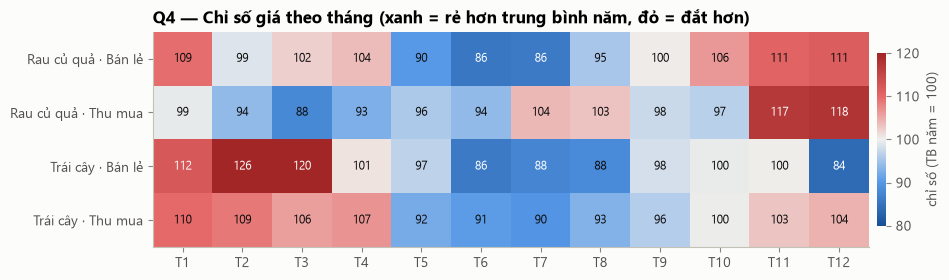

In [21]:
season = q(f"""
SELECT nhom_san_pham, cap_gia, month, {AVG} AS gia_tb FROM ttns.cube_thang_nhom_tinh_loaigia
WHERE cap_gia IN ('Bán lẻ', 'Thu mua') GROUP BY nhom_san_pham, cap_gia, month""")
season["chi_so"] = season.groupby(["nhom_san_pham", "cap_gia"])["gia_tb"].transform(lambda s: s / s.mean() * 100)
heat = season.pivot_table(index=["nhom_san_pham", "cap_gia"], columns="month", values="chi_so")
fig, ax = plt.subplots(figsize=(11, 2.8))
DIV = LinearSegmentedColormap.from_list("d", ["#184f95", "#5598e7", "#f0efec", "#e66767", "#a32626"])
im = ax.imshow(heat.values, cmap=DIV, vmin=80, vmax=120, aspect="auto")
ax.grid(False)
ax.set_xticks(range(12), [f"T{m}" for m in heat.columns])
ax.set_yticks(range(len(heat)), [f"{a} · {b}" for a, b in heat.index])
for i in range(heat.shape[0]):
    for j in range(12):
        ax.text(j, i, f"{heat.values[i, j]:.0f}", ha="center", va="center", fontsize=8.5,
                color="white" if abs(heat.values[i, j] - 100) > 12 else INK)
cb = fig.colorbar(im, ax=ax, shrink=0.8, pad=0.01)
cb.set_label("chỉ số (TB năm = 100)", color=INK2)
cb.outline.set_visible(False)
ax.set_title("Q4 — Chỉ số giá theo tháng (xanh = rẻ hơn trung bình năm, đỏ = đắt hơn)")
fig.savefig("figures/05_mua_vu.png")
plt.show()

## 6. Tổng kết phần kho dữ liệu & OLAP
| Yêu cầu (Bài 12) | Đáp ứng trong dự án |
|---|---|
| Mô tả nguồn, số bản ghi, số thuộc tính, thời gian | Mục 1 |
| Tỷ lệ giá trị thiếu và cách xử lý từng cột | Bảng chất lượng dữ liệu, mục 1 |
| Lược đồ hình sao, bảng sự kiện, bảng chiều, độ mịn | Mục 2.1–2.2: 1 bảng sự kiện, **4 chiều** |
| Ít nhất 3 chiều và một phân cấp khái niệm | 4 chiều, **mỗi chiều có phân cấp** (tháng→quý→năm, mặt hàng→sản phẩm→nhóm, tỉnh cũ→tỉnh mới→vùng, loại giá→cấp giá) |
| Giải thích vì sao chọn độ mịn | Mục 2.2 |
| Cài đặt kho trên một hệ quản trị | ClickHouse; DDL trong `dags/pipelines/ttns/schema.py` |
| Mã ETL nạp dữ liệu từ nguồn vào kho | Airflow DAG `ttns_price_pipeline` (Extract → MinIO → Transform → CDC → Load) |
| Tính trước ít nhất hai khối con và nêu lý do | **3 khối con** chọn bằng thuật toán tham lam trên kích thước thật (mục 3), lợi ích đo bằng `query_log` (3.1) |
| Trình diễn đủ năm thao tác OLAP trên dữ liệu thật | Mục 4.1–4.6 + `CUBE` / `ROLLUP` (4.7), giao diện tương tác trong ứng dụng `app/` |
| Chạy lại được từ đầu bằng một lệnh | `run_all.sh` |